In [ ]:
%pip install -q scanpy anndata h5py scipy pandas numpy matplotlib seaborn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [ ]:
from pathlib import Path
import json
import random
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

sc.settings.verbosity = 2
warnings.filterwarnings("default")

print("Scanpy version:", sc.__version__)
print("AnnData version:", ad.__version__)
print("Random seed:", SEED)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Scanpy version: 1.12.4
AnnData version: 0.13.4
Random seed: 42


/tmp/ipykernel_8143/1753191822.py:22: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy version:", sc.__version__)
/tmp/ipykernel_8143/1753191822.py:23: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print("AnnData version:", ad.__version__)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive")

print("Drive connected:", DRIVE_ROOT.exists())
print("Root path:", DRIVE_ROOT)


Mounted at /content/drive
Drive connected: True
Root path: /content/drive/MyDrive


Cell 4 — Create the project workspace

In [ ]:
PROJECT_DIR = Path("/content/drive/MyDrive/spatial_ml_breast_cancer")

folders = [
    "configs",
    "data/processed",
    "results/figures",
    "results/tables",
    "reports",
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project workspace:", PROJECT_DIR)

for folder in folders:
    print("Created/checked:", folder)

Project workspace: /content/drive/MyDrive/spatial_ml_breast_cancer
Created/checked: configs
Created/checked: data/processed
Created/checked: results/figures
Created/checked: results/tables
Created/checked: reports


Cell 5 — Download the dataset directly

In [ ]:
from pathlib import Path
import subprocess

DATA_DIR = Path("/content/xenium_breast_rep1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = (
    "https://cf.10xgenomics.com/samples/xenium/1.0.1/"
    "Xenium_FFPE_Human_Breast_Cancer_Rep1/"
    "Xenium_FFPE_Human_Breast_Cancer_Rep1"
)

files_to_download = {
    "cell_feature_matrix.h5": f"{BASE_URL}_cell_feature_matrix.h5",
    "cells.csv.gz": f"{BASE_URL}_cells.csv.gz",
}

for filename, url in files_to_download.items():
    destination = DATA_DIR / filename

    if destination.exists() and destination.stat().st_size > 0:
        print(f"Already downloaded: {filename}")
        continue

    print(f"\nDownloading {filename}...")

    subprocess.run(
        ["wget", "-c", "-O", str(destination), url],
        check=True
    )

    if destination.stat().st_size == 0:
        raise RuntimeError(f"Downloaded file is empty: {filename}")

    print(f"Saved: {destination}")
    print(f"Size: {destination.stat().st_size / 1e6:.2f} MB")

print("\nDownload step completed.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Saved: /content/xenium_breast_rep1/cell_feature_matrix.h5
Size: 12.15 MB

Saved: /content/xenium_breast_rep1/cells.csv.gz
Size: 7.93 MB

Download step completed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Cell 6 — Verify both files

In [ ]:
for filename in ["cell_feature_matrix.h5", "cells.csv.gz"]:
    path = DATA_DIR / filename

    print(
        filename,
        "| exists:", path.exists(),
        "| size:", f"{path.stat().st_size / 1e6:.2f} MB"
        if path.exists() else "missing"
    )

assert (DATA_DIR / "cell_feature_matrix.h5").exists()
assert (DATA_DIR / "cells.csv.gz").exists()

print("\nBoth required files are present.")

cell_feature_matrix.h5 | exists: True | size: 12.15 MB
cells.csv.gz | exists: True | size: 7.93 MB

Both required files are present.


Cell 7: Load the gene expression matrix

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path("/content/xenium_breast_rep1")

matrix_path = DATA_DIR / "cell_feature_matrix.h5"

adata = sc.read_10x_h5(matrix_path)

# Make gene names unique if any are duplicated
adata.var_names_make_unique()

print("Expression matrix loaded successfully!")
print("Number of cells:", adata.n_obs)
print("Number of genes:", adata.n_vars)
print("Expression matrix type:", type(adata.X))
print("\nFirst 10 gene names:")
print(adata.var_names[:10].tolist())

reading /content/xenium_breast_rep1/cell_feature_matrix.h5
 (0:00:01)
Expression matrix loaded successfully!
Number of cells: 167780
Number of genes: 313
Expression matrix type: <class 'scipy.sparse._csr.csr_matrix'>

First 10 gene names:
['ABCC11', 'ACTA2', 'ACTG2', 'ADAM9', 'ADGRE5', 'ADH1B', 'ADIPOQ', 'AGR3', 'AHSP', 'AIF1']


/usr/local/lib/python3.13/dist-packages/anndata/compat/__init__.py:249: Pandas4Warning: The 'future.infer_string' option is deprecated and will be removed in pandas 4.0. Inferring str dtype for string data has been the default since pandas 3.0, and it will no longer be possible to disable it.
  return a if pd.options.future.infer_string else a.astype(object)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=ut

Cell 8: Load and inspect cell metadata

In [ ]:
metadata_path = DATA_DIR / "cells.csv.gz"

metadata = pd.read_csv(metadata_path)

print("Metadata loaded successfully!")
print("Metadata dimensions:", metadata.shape)
print("\nMetadata columns:")
print(metadata.columns.tolist())

print("\nFirst five rows:")
display(metadata.head())

Metadata loaded successfully!
Metadata dimensions: (167780, 9)

Metadata columns:
['cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area']

First five rows:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,cell_id,x_centroid,y_centroid,transcript_counts,control_probe_counts,control_codeword_counts,total_counts,cell_area,nucleus_area
0,1,847.259912,326.191365,28,1,0,29,58.387031,26.642188
1,2,826.341995,328.031830,94,0,0,94,197.016719,42.130781
2,3,848.766919,331.743187,9,0,0,9,16.256250,12.688906
3,4,824.228409,334.252643,11,0,0,11,42.311406,10.069844
4,5,841.357538,332.242505,48,0,0,48,107.652500,37.479688


Cell 9: Check whether the files describe the same cells

In [ ]:
print("Expression cell IDs (first 5):")
print(adata.obs_names[:5].tolist())

print("\nMetadata columns:")
print(metadata.columns.tolist())

# Find likely cell identifier column
possible_id_columns = [
    col for col in metadata.columns
    if col.lower() in ["cell_id", "cellid", "barcode"]
]

print("\nPotential ID columns:", possible_id_columns)

Expression cell IDs (first 5):
['1', '2', '3', '4', '5']

Metadata columns:
['cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area']

Potential ID columns: ['cell_id']


Cell 10 — Inspect and validate identifiers

In [ ]:
# Find the cell ID column automatically
id_candidates = [
    col for col in metadata.columns
    if col.lower() in ["cell_id", "cellid", "barcode"]
]

if len(id_candidates) != 1:
    raise ValueError(
        f"Expected one cell ID column, found: {id_candidates}. "
        "Inspect metadata.columns and select the correct ID column."
    )

id_col = id_candidates[0]

# Convert IDs to strings for consistent comparison
expression_ids = pd.Index(adata.obs_names.astype(str))
metadata_ids = pd.Index(metadata[id_col].astype(str))

print("Expression IDs unique:", expression_ids.is_unique)
print("Metadata IDs unique:", metadata_ids.is_unique)

print("Expression cells:", len(expression_ids))
print("Metadata rows:", len(metadata_ids))

print("IDs present in both:", len(expression_ids.intersection(metadata_ids)))
print("Expression IDs missing from metadata:", len(expression_ids.difference(metadata_ids)))
print("Metadata IDs missing from expression:", len(metadata_ids.difference(expression_ids)))

Expression IDs unique: True
Metadata IDs unique: True
Expression cells: 167780
Metadata rows: 167780
IDs present in both: 167780
Expression IDs missing from metadata: 0
Metadata IDs missing from expression: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Cell 11 — Check the spatial coordinate columns

In [ ]:
print("Available metadata columns:")
print(metadata.columns.tolist())

coordinate_candidates = {
    "x": ["x_centroid", "center_x", "x"],
    "y": ["y_centroid", "center_y", "y"],
}

coordinate_columns = {}

for axis, candidates in coordinate_candidates.items():
    matches = [
        col for col in metadata.columns
        if col.lower() in candidates
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Could not uniquely identify the {axis}-coordinate column. "
            f"Candidates found: {matches}. Inspect metadata.columns."
        )

    coordinate_columns[axis] = matches[0]

print("\nX coordinate column:", coordinate_columns["x"])
print("Y coordinate column:", coordinate_columns["y"])

coords = metadata[
    [coordinate_columns["x"], coordinate_columns["y"]]
].apply(pd.to_numeric, errors="coerce")

print("\nMissing X coordinates:", coords.iloc[:, 0].isna().sum())
print("Missing Y coordinates:", coords.iloc[:, 1].isna().sum())
print("Non-finite coordinate values:", (~np.isfinite(coords.to_numpy())).sum())

Available metadata columns:
['cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area']

X coordinate column: x_centroid
Y coordinate column: y_centroid

Missing X coordinates: 0
Missing Y coordinates: 0
Non-finite coordinate values: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Cell 12 — Match metadata to expression cells

In [ ]:
# Stop if IDs are duplicated; matching would be ambiguous
if not expression_ids.is_unique:
    raise ValueError("Expression cell IDs are duplicated.")

if not metadata_ids.is_unique:
    raise ValueError("Metadata cell IDs are duplicated.")

# Keep only metadata rows whose IDs occur in the expression matrix
metadata_indexed = metadata.copy()
metadata_indexed[id_col] = metadata_ids
metadata_indexed = metadata_indexed.set_index(id_col, drop=False)

matched_ids = expression_ids[expression_ids.isin(metadata_indexed.index)]

if len(matched_ids) == 0:
    raise ValueError(
        "No matching cell IDs found. Inspect the ID formats before proceeding."
    )

# Align metadata to the expression matrix order
aligned_metadata = metadata_indexed.loc[matched_ids].copy()

# Subset expression data in the same order
adata_aligned = adata[matched_ids.astype(str), :].copy()

# Make sure both objects have the same cell ordering
assert list(adata_aligned.obs_names.astype(str)) == list(
    aligned_metadata.index.astype(str)
)

print("Expression cells before matching:", adata.n_obs)
print("Metadata rows before matching:", len(metadata))
print("Matched cells:", adata_aligned.n_obs)
print("Genes:", adata_aligned.n_vars)
print("Cell ordering verified:", True)

Expression cells before matching: 167780
Metadata rows before matching: 167780
Matched cells: 167780
Genes: 313
Cell ordering verified: True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Cell 13 — Attach metadata and spatial coordinates

In [ ]:
# Attach metadata to the matched AnnData object
adata_aligned.obs = aligned_metadata.copy()

# Store coordinates in AnnData's standard spatial-observation slot
xy = aligned_metadata[
    [coordinate_columns["x"], coordinate_columns["y"]]
].apply(pd.to_numeric, errors="coerce").to_numpy()

if not np.isfinite(xy).all():
    raise ValueError(
        "Some matched cells have missing or non-finite coordinates. "
        "Inspect these rows before proceeding."
    )

adata_aligned.obsm["spatial"] = xy

# Set the usual coordinate names for clarity
adata_aligned.uns["spatial_coordinate_columns"] = [
    coordinate_columns["x"],
    coordinate_columns["y"],
]

print("Aligned AnnData object:", adata_aligned)
print("Spatial coordinate shape:", adata_aligned.obsm["spatial"].shape)
print("Missing spatial coordinates:", np.isnan(adata_aligned.obsm["spatial"]).sum())
print("Metadata columns attached:", adata_aligned.obs.columns.tolist())

Aligned AnnData object: AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial_coordinate_columns'
    obsm: 'spatial'
    layers: None (.X)
Spatial coordinate shape: (167780, 2)
Missing spatial coordinates: 0
Metadata columns attached: ['cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Cell 14 — Run essential validation checks

In [ ]:
assert adata_aligned.n_obs == adata_aligned.obsm["spatial"].shape[0]
assert adata_aligned.obsm["spatial"].shape[1] == 2
assert adata_aligned.obs_names.is_unique
assert adata_aligned.var_names.is_unique

print("All structural checks passed.")
print("Cells:", adata_aligned.n_obs)
print("Genes:", adata_aligned.n_vars)
print("Expression matrix is sparse:", sp.issparse(adata_aligned.X))
print("Coordinates stored:", "spatial" in adata_aligned.obsm)

All structural checks passed.
Cells: 167780
Genes: 313
Expression matrix is sparse: True
Coordinates stored: True


Cell 15: Quality-control summary

In [ ]:
# Cell 15: Dataset quality-control summary

X = adata_aligned.X

if sp.issparse(X):
    counts_per_cell = np.asarray(X.sum(axis=1)).ravel()
    genes_detected_per_cell = np.asarray((X > 0).sum(axis=1)).ravel()
else:
    counts_per_cell = np.asarray(X.sum(axis=1)).ravel()
    genes_detected_per_cell = np.asarray((X > 0).sum(axis=1)).ravel()

qc_summary = pd.DataFrame({
    "metric": [
        "Number of cells",
        "Number of genes",
        "Total expression counts",
        "Median counts per cell",
        "Mean counts per cell",
        "Median detected genes per cell",
        "Cells with zero total counts",
        "Cells with zero detected genes",
        "Cells with missing metadata values",
        "Cells with missing spatial coordinates",
    ],
    "value": [
        adata_aligned.n_obs,
        adata_aligned.n_vars,
        int(counts_per_cell.sum()),
        float(np.median(counts_per_cell)),
        float(np.mean(counts_per_cell)),
        float(np.median(genes_detected_per_cell)),
        int((counts_per_cell == 0).sum()),
        int((genes_detected_per_cell == 0).sum()),
        int(adata_aligned.obs.isna().any(axis=1).sum()),
        int((~np.isfinite(adata_aligned.obsm["spatial"]).all(axis=1)).sum()),
    ]
})

display(qc_summary)

,metric,value
0,Number of cells,1.677800e+05
1,Number of genes,3.130000e+02
2,Total expression counts,3.210296e+07
3,Median counts per cell,1.640000e+02
4,Mean counts per cell,1.913396e+02
5,Median detected genes per cell,6.400000e+01
6,Cells with zero total counts,1.417000e+03
7,Cells with zero detected genes,1.417000e+03
8,Cells with missing metadata values,0.000000e+00
9,Cells with missing spatial coordinates,0.000000e+00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Cell 16 — Visualize expression quality

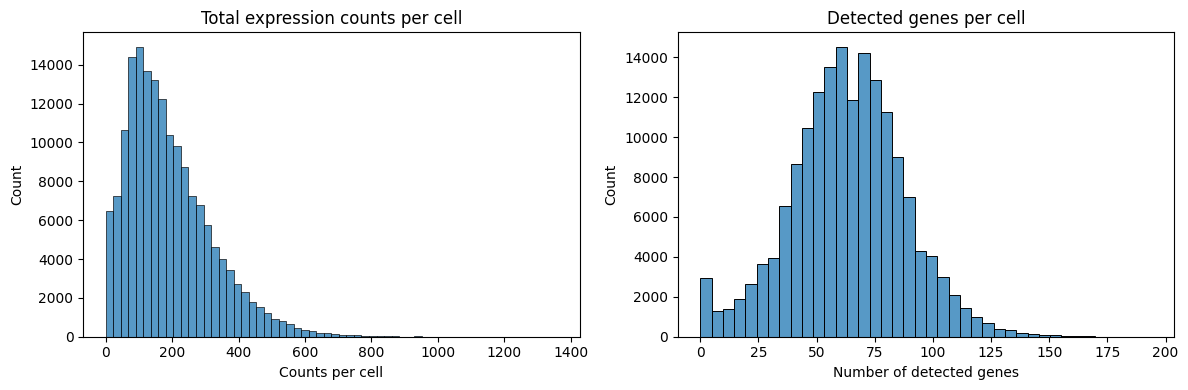

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Cell 16: Distribution of expression counts and detected genes

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    counts_per_cell,
    bins=60,
    ax=axes[0]
)
axes[0].set_title("Total expression counts per cell")
axes[0].set_xlabel("Counts per cell")

sns.histplot(
    genes_detected_per_cell,
    bins=40,
    ax=axes[1]
)
axes[1].set_title("Detected genes per cell")
axes[1].set_xlabel("Number of detected genes")

plt.tight_layout()
plt.show()

Cell 17 — Check the spatial layout

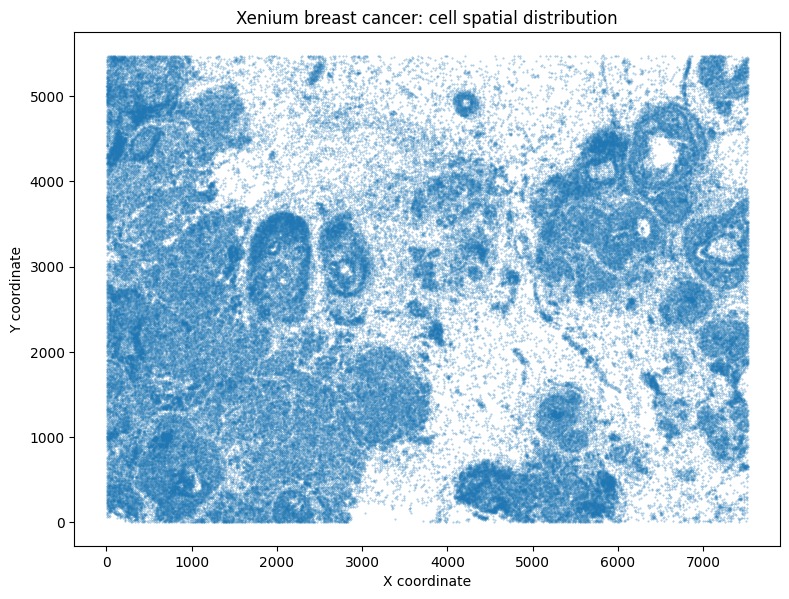

In [ ]:
# Cell 17: Plot cell positions

xy = adata_aligned.obsm["spatial"]

plt.figure(figsize=(8, 7))
plt.scatter(
    xy[:, 0],
    xy[:, 1],
    s=0.15,
    alpha=0.5
)

plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title("Xenium breast cancer: cell spatial distribution")
plt.gca().set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

Cell 18 — Save the validated data and QC report

In [ ]:
# Cell 18: Save outputs

output_dir = PROJECT_DIR / "data" / "processed"
tables_dir = PROJECT_DIR / "results" / "tables"
reports_dir = PROJECT_DIR / "reports"

output_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

h5ad_path = output_dir / "xenium_breast_validated.h5ad"
qc_path = tables_dir / "quality_control_summary.csv"
report_path = reports_dir / "notebook_01_validation.json"

adata_aligned.write_h5ad(h5ad_path)
qc_summary.to_csv(qc_path, index=False)

report = {
    "cells": int(adata_aligned.n_obs),
    "genes": int(adata_aligned.n_vars),
    "matched_metadata_rows": int(len(aligned_metadata)),
    "coordinate_columns": list(adata_aligned.uns["spatial_coordinate_columns"]),
    "random_seed": SEED,
    "expression_matrix_sparse": bool(sp.issparse(adata_aligned.X)),
    "validated_dataset_path": str(h5ad_path),
}

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("Saved validated AnnData:", h5ad_path)
print("Saved QC summary:", qc_path)
print("Saved validation report:", report_path)

/usr/local/lib/python3.13/dist-packages/anndata/_io/specs/methods.py:1269: Pandas4Warning: The 'future.infer_string' option is deprecated and will be removed in pandas 4.0. Inferring str dtype for string data has been the default since pandas 3.0, and it will no longer be possible to disable it.
  and not pd.options.future.infer_string
/usr/local/lib/python3.13/dist-packages/anndata/_io/specs/methods.py:1269: Pandas4Warning: The 'future.infer_string' option is deprecated and will be removed in pandas 4.0. Inferring str dtype for string data has been the default since pandas 3.0, and it will no longer be possible to disable it.
  and not pd.options.future.infer_string
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/us

Saved validated AnnData: /content/drive/MyDrive/spatial_ml_breast_cancer/data/processed/xenium_breast_validated.h5ad
Saved QC summary: /content/drive/MyDrive/spatial_ml_breast_cancer/results/tables/quality_control_summary.csv
Saved validation report: /content/drive/MyDrive/spatial_ml_breast_cancer/reports/notebook_01_validation.json


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
